In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
os.chdir(os.path.abspath('..'))

In [2]:
import pandas as pd
from pprint import pprint
from tqdm import tqdm
import json
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import os

from utils.anthroscore_utils import (
    separate_sentences,
    get_scores_no_duplicates,
    plot_scores,
    grouped_stats,
)

plots_dir = "plots/"
try:
    os.mkdir(plots_dir)
    print(f"Directory '{plots_dir}' created successfully.")
except FileExistsError:
    print(f"Directory '{plots_dir}' already exists.")

import spacy
nlp = spacy.load('en_core_web_lg')

Directory 'plots/' already exists.


OSError: [E050] Can't find model 'en_core_web_lg'. It doesn't seem to be a Python package or a valid path to a data directory.

In [ ]:
ai_terms = open(f"config_files/ai_terms.txt", "r").read()
ki_terms = open(f"config_files/ki_terms.txt", "r").read()

### Input to Anthroscore

In [ ]:
# anthroscore for translated (english) sentences, without "palm"
terminal_input = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name translation --entities {ai_terms} --output_file generated_data/Anthroscore_results/KI_sentences_no_palm_eng_scores.csv --text_id_name id '''
terminal_input

"python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name translation --entities  'palm' 'lms' 'llama' 'Transformern' 'Language models' 'Language model' 'gpt' 'plms' 'pre-trained language models' 'gpt-2' 'xlnet' 'large language models' 'llms' 'gpt-3' 'Foundation model' 'gpt-neo' 'gpt-j' 'chatgpt' 'gpt-4' 'AI' 'Artificial intelligence' 'ChatGPT' 'AI' 'Copilot' 'Gemini' 'Chatbot' 'LLM' 'Chat GPT' 'Language model' 'AI model' 'AI system' 'AI tool' 'Artificial Intelligence' 'AI application' --output_file generated_data/Anthroscore_results/KI_sentences_no_palm_eng_scores.csv --text_id_name id "

In [54]:
# anthroscore for german sentences, without "palm"
terminal_input_ger = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name text --entities {ki_terms} --output_file generated_data/Anthroscore_results/KI_sentences_no_palm_ger_scores.csv --text_id_name id '''
terminal_input_ger

"python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name text --entities  'palm' 'lms' 'llama' 'Transformer' 'Sprachmodelle' 'Sprachmodell' 'gpt' 'plms' 'vortrainierte Sprachmodelle' 'gpt-2' 'xlnet' 'große Sprachmodelle' 'llms' 'gpt-3' 'Stiftungsmodell' 'gpt-neo' 'gpt-j' 'chatgpt' 'gpt-4' 'KI' 'Künstliche Intelligenz' 'ChatGPT' 'AI' 'Copilot' 'Gemini' 'Chatbot' 'LLM' 'Chat-GPT' 'Sprachmodell' 'KI-Modell' 'KI-System' 'KI-Tool' 'Artificial Intelligence' 'KI-Anwendung' --output_file generated_data/Anthroscore_results/KI_sentences_no_palm_ger_scores.csv --text_id_name id "

In [55]:
# anthroscore for translated (english) sentences, with "palm"
terminal_input = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name translation --entities {ai_terms} --output_file generated_data/Anthroscore_results/KI_sentences_eng_scores.csv --text_id_name id '''
terminal_input

"python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name translation --entities  'palm' 'lms' 'llama' 'Transformern' 'Language models' 'Language model' 'gpt' 'plms' 'pre-trained language models' 'gpt-2' 'xlnet' 'large language models' 'llms' 'gpt-3' 'Foundation model' 'gpt-neo' 'gpt-j' 'chatgpt' 'gpt-4' 'AI' 'Artificial intelligence' 'ChatGPT' 'AI' 'Copilot' 'Gemini' 'Chatbot' 'LLM' 'Chat GPT' 'Language model' 'AI model' 'AI system' 'AI tool' 'Artificial Intelligence' 'AI application' --output_file generated_data/Anthroscore_results/KI_sentences_eng_scores.csv --text_id_name id "

In [56]:
# anthroscore for german sentences, with "palm"
terminal_input_ger = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name text --entities {ki_terms} --output_file generated_data/Anthroscore_results/KI_sentences_ger_scores.csv --text_id_name id '''
terminal_input_ger

"python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name text --entities  'palm' 'lms' 'llama' 'Transformer' 'Sprachmodelle' 'Sprachmodell' 'gpt' 'plms' 'vortrainierte Sprachmodelle' 'gpt-2' 'xlnet' 'große Sprachmodelle' 'llms' 'gpt-3' 'Stiftungsmodell' 'gpt-neo' 'gpt-j' 'chatgpt' 'gpt-4' 'KI' 'Künstliche Intelligenz' 'ChatGPT' 'AI' 'Copilot' 'Gemini' 'Chatbot' 'LLM' 'Chat-GPT' 'Sprachmodell' 'KI-Modell' 'KI-System' 'KI-Tool' 'Artificial Intelligence' 'KI-Anwendung' --output_file generated_data/Anthroscore_results/KI_sentences_ger_scores.csv --text_id_name id "

In [57]:
# anthroscore for german texts, with "palm"
terminal_input_ger = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_full_translated.csv --text_column_name text --entities {ki_terms} --output_file generated_data/Anthroscore_results/KI_texts_ger_scores.csv --text_id_name id '''
terminal_input_ger

"python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_full_translated.csv --text_column_name text --entities  'palm' 'lms' 'llama' 'Transformer' 'Sprachmodelle' 'Sprachmodell' 'gpt' 'plms' 'vortrainierte Sprachmodelle' 'gpt-2' 'xlnet' 'große Sprachmodelle' 'llms' 'gpt-3' 'Stiftungsmodell' 'gpt-neo' 'gpt-j' 'chatgpt' 'gpt-4' 'KI' 'Künstliche Intelligenz' 'ChatGPT' 'AI' 'Copilot' 'Gemini' 'Chatbot' 'LLM' 'Chat-GPT' 'Sprachmodell' 'KI-Modell' 'KI-System' 'KI-Tool' 'Artificial Intelligence' 'KI-Anwendung' --output_file generated_data/Anthroscore_results/KI_texts_ger_scores.csv --text_id_name id "

In [58]:
# anthroscore for translated texts, with "palm"
terminal_input_ger = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_full_translated.csv --text_column_name translation --entities {ai_terms} --output_file generated_data/Anthroscore_results/KI_texts_eng_scores.csv --text_id_name id '''
terminal_input_ger

"python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_full_translated.csv --text_column_name translation --entities  'palm' 'lms' 'llama' 'Transformern' 'Language models' 'Language model' 'gpt' 'plms' 'pre-trained language models' 'gpt-2' 'xlnet' 'large language models' 'llms' 'gpt-3' 'Foundation model' 'gpt-neo' 'gpt-j' 'chatgpt' 'gpt-4' 'AI' 'Artificial intelligence' 'ChatGPT' 'AI' 'Copilot' 'Gemini' 'Chatbot' 'LLM' 'Chat GPT' 'Language model' 'AI model' 'AI system' 'AI tool' 'Artificial Intelligence' 'AI application' --output_file generated_data/Anthroscore_results/KI_texts_eng_scores.csv --text_id_name id "

In [59]:
# anthroscore for german sentences of Leipzig corpus, with "palm"
terminal_input_ger = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/Leipzig_KI_sentences_24_1M_translated.csv --text_column_name text --entities {ki_terms} --output_file generated_data/Anthroscore_results/Leipzig_KI_sentences_ger_scores.csv --text_id_name id '''
terminal_input_ger

"python3 anthroscore/src/get_anthroscore.py --input_file generated_data/Leipzig_KI_sentences_24_1M_translated.csv --text_column_name text --entities  'palm' 'lms' 'llama' 'Transformer' 'Sprachmodelle' 'Sprachmodell' 'gpt' 'plms' 'vortrainierte Sprachmodelle' 'gpt-2' 'xlnet' 'große Sprachmodelle' 'llms' 'gpt-3' 'Stiftungsmodell' 'gpt-neo' 'gpt-j' 'chatgpt' 'gpt-4' 'KI' 'Künstliche Intelligenz' 'ChatGPT' 'AI' 'Copilot' 'Gemini' 'Chatbot' 'LLM' 'Chat-GPT' 'Sprachmodell' 'KI-Modell' 'KI-System' 'KI-Tool' 'Artificial Intelligence' 'KI-Anwendung' --output_file generated_data/Anthroscore_results/Leipzig_KI_sentences_ger_scores.csv --text_id_name id "

In [60]:
# anthroscore for translated (english) sentences of Leipzig corpus, with "palm"
terminal_input = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/Leipzig_KI_sentences_24_1M_translated.csv --text_column_name translation --entities {ai_terms} --output_file generated_data/Anthroscore_results/Leipzig_KI_sentences_eng_scores.csv --text_id_name id '''
terminal_input

"python3 anthroscore/src/get_anthroscore.py --input_file generated_data/Leipzig_KI_sentences_24_1M_translated.csv --text_column_name translation --entities  'palm' 'lms' 'llama' 'Transformern' 'Language models' 'Language model' 'gpt' 'plms' 'pre-trained language models' 'gpt-2' 'xlnet' 'large language models' 'llms' 'gpt-3' 'Foundation model' 'gpt-neo' 'gpt-j' 'chatgpt' 'gpt-4' 'AI' 'Artificial intelligence' 'ChatGPT' 'AI' 'Copilot' 'Gemini' 'Chatbot' 'LLM' 'Chat GPT' 'Language model' 'AI model' 'AI system' 'AI tool' 'Artificial Intelligence' 'AI application' --output_file generated_data/Anthroscore_results/Leipzig_KI_sentences_eng_scores.csv --text_id_name id "

In [ ]:
# TODO: split translated_full sentences and input to anthroscore
# separate_sentences(sents, nlp) is defined in anthroscore_utils.py

# input to Anthroscore
terminal_input_split = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_full_translated.csv --text_column_name text --entities {ai_terms} --output_file generated_data/Anthroscore_results/KI_sentences_ger_scores_split.csv --text_id_name id '''
terminal_input_split

### AnthroScore Results

In [ ]:
# get all score as dict
main_dir = "generated_data/Anthroscore_results"
all_dfs_dict ={}
for dir in tqdm(os.listdir(main_dir)):
    if "sentence_scores" in str(dir):
        #print(os.path.join(main_dir,dir))
        data = get_scores_no_duplicates(os.path.join(main_dir,dir))
        all_dfs_dict[dir] = data

100%|██████████| 14/14 [00:00<00:00, 293.25it/s]


In [66]:
grouped_ai = grouped_stats(all_dfs_dict)
grouped_ai

anthroscore not found in KI_sentences_full_translated_sentence_scores.csv


original_term,AI,Artificial Intelligence,Chatbot,Copilot,Gemini,KI,Künstliche Intelligenz,Sprachmodell,Sprachmodelle,Transformer,...,palm,Artificial intelligence,LLM,Language model,Language models,Transformern,llama,Stiftungsmodell,Foundation model,transformer
anthro_re_sentence_scores.csv,-0.190143,-1.669027,2.176390,0.512022,0.348860,1.298266,1.400685,0.329528,1.387546,1.524689,...,0.414778,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Leipzig_KI_sentences_24_1M_translated_sentence_scores_eng.csv,-2.338583,NaN,-0.995608,-2.642864,-2.358162,NaN,NaN,NaN,NaN,NaN,...,0.173287,-2.589019,-2.492303,-1.552267,-2.393365,0.118957,0.120712,NaN,NaN,NaN
KI_sentences_translated_sentence_scores_ger.csv,0.578310,0.959324,1.121539,0.920569,1.112699,0.705219,0.806313,0.444906,-0.346161,0.967429,...,0.484574,NaN,NaN,NaN,NaN,NaN,1.400988,0.332253,NaN,NaN
KI_sentences_translated_sentence_scores_eng.csv,0.127964,NaN,-0.813953,3.966575,-1.161637,NaN,NaN,NaN,NaN,NaN,...,-0.588362,-1.918051,NaN,0.462792,-2.298190,NaN,1.654053,NaN,-2.881447,-0.606443
Leipzig_KI_sentences_24_1M_translated_sentence_scores_ger.csv,0.486637,-0.060502,1.117849,0.735490,0.836218,0.925826,0.900862,0.957325,0.720629,-0.311202,...,-0.527683,NaN,0.053732,NaN,NaN,NaN,-0.511585,NaN,NaN,NaN
anthro_re_translated_sentence_scores.csv,-0.709383,NaN,-2.936150,1.677954,-1.538398,NaN,NaN,NaN,NaN,NaN,...,-1.203313,-2.265472,NaN,1.405217,-1.841545,-2.542941,NaN,NaN,NaN,NaN


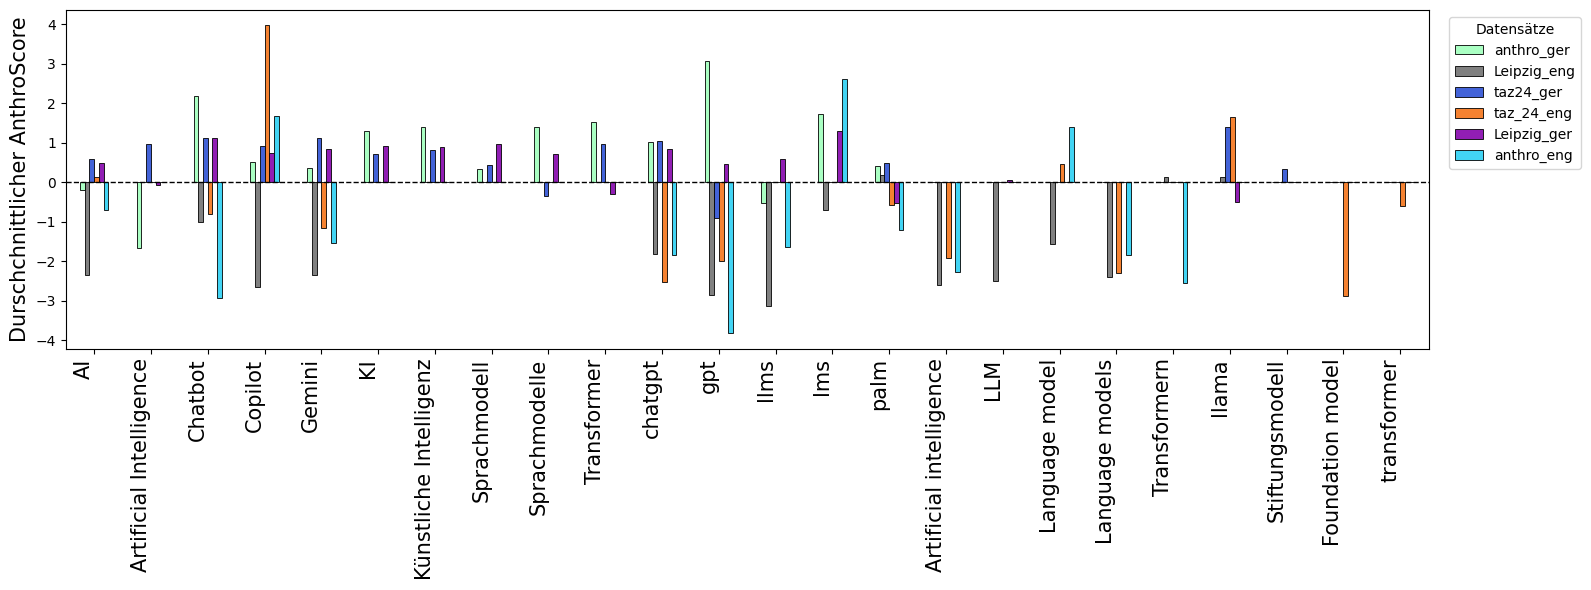

In [97]:
colors = ["#aaffc3", "grey", "#4363d8", "#f58231", "#911eb4", "#42d4f4"]
legend_names = ["anthro_ger", "Leipzig_eng", "taz24_ger", "taz_24_eng", "Leipzig_ger", "anthro_eng"]

grouped_plot = grouped_ai.copy()
grouped_plot.index = legend_names
color_dict = dict(zip(legend_names, colors))

fig, ax = plt.subplots(figsize=(16, 6))
grouped_plot.T.plot(kind="bar", ax=ax, color=color_dict, edgecolor="black", linewidth=0.6)
ax.axhline(0, color='black', linewidth=1, linestyle='--')
ax.set_ylabel("Durschchnittlicher AnthroScore", fontsize=15)
ax.set_xlabel("")
ax.set_xticklabels(grouped_plot.columns, rotation=90, fontsize=15, ha="right")
ax.legend(title="Datensätze", bbox_to_anchor=(1.01, 1), loc="upper left")

fig.tight_layout()
fig.savefig(plots_dir + "grouped_ai_per_row.png")
plt.show()

boxplot
ger: count    1950.000000
mean        0.833269
std         1.977167
min        -9.608369
25%        -0.256358
50%         0.900646
75%         2.260459
max        10.728700
Name: anthroscore, dtype: float64
-------------------
eng: count    1241.000000
mean       -2.185748
std         2.464127
min        -9.978442
25%        -3.859204
50%        -2.370155
75%        -0.666179
max         6.291591
Name: anthroscore, dtype: float64


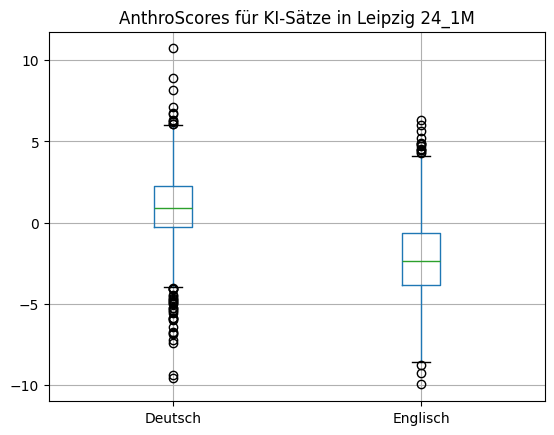

In [68]:
text_scores = get_scores_no_duplicates("generated_data/Anthroscore_results/Leipzig_KI_sentences_24_1M_translated_sentence_scores_ger.csv")
translated_scores = get_scores_no_duplicates("generated_data/Anthroscore_results/Leipzig_KI_sentences_24_1M_translated_sentence_scores_eng.csv")

plot_scores(translated_scores, text_scores, "AnthroScores für KI-Sätze in Leipzig 24_1M")

## Anthroscore für anthropomorphic sentences from regex search?

In [69]:
# get translated sentences corresponding to anthro sentences
terminal_input = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/anthro_re_translated.csv --text_column_name translation --entities {ai_terms} --output_file generated_data/Anthroscore_results/generated_data/anthro_re_translated_eng_scores.csv --text_id_name id '''
terminal_input

"python3 anthroscore/src/get_anthroscore.py --input_file generated_data/anthro_re_translated.csv --text_column_name translation --entities  'palm' 'lms' 'llama' 'Transformern' 'Language models' 'Language model' 'gpt' 'plms' 'pre-trained language models' 'gpt-2' 'xlnet' 'large language models' 'llms' 'gpt-3' 'Foundation model' 'gpt-neo' 'gpt-j' 'chatgpt' 'gpt-4' 'AI' 'Artificial intelligence' 'ChatGPT' 'AI' 'Copilot' 'Gemini' 'Chatbot' 'LLM' 'Chat GPT' 'Language model' 'AI model' 'AI system' 'AI tool' 'Artificial Intelligence' 'AI application' --output_file generated_data/Anthroscore_results/generated_data/anthro_re_translated_eng_scores.csv --text_id_name id "

In [70]:
# get anthro sentences and ki terms

terminal_input = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/anthro_re_translated.csv --text_column_name text --entities {ki_terms} --output_file generated_data/Anthroscore_results/generated_data/anthro_re__scores.csv --text_id_name id '''
terminal_input

"python3 anthroscore/src/get_anthroscore.py --input_file generated_data/anthro_re_translated.csv --text_column_name text --entities  'palm' 'lms' 'llama' 'Transformer' 'Sprachmodelle' 'Sprachmodell' 'gpt' 'plms' 'vortrainierte Sprachmodelle' 'gpt-2' 'xlnet' 'große Sprachmodelle' 'llms' 'gpt-3' 'Stiftungsmodell' 'gpt-neo' 'gpt-j' 'chatgpt' 'gpt-4' 'KI' 'Künstliche Intelligenz' 'ChatGPT' 'AI' 'Copilot' 'Gemini' 'Chatbot' 'LLM' 'Chat-GPT' 'Sprachmodell' 'KI-Modell' 'KI-System' 'KI-Tool' 'Artificial Intelligence' 'KI-Anwendung' --output_file generated_data/Anthroscore_results/generated_data/anthro_re__scores.csv --text_id_name id "

boxplot
ger: count    319.000000
mean       1.133155
std        1.992087
min       -7.993310
25%       -0.007247
50%        1.297625
75%        2.274001
max        7.140223
Name: anthroscore, dtype: float64
-------------------
eng: count    193.000000
mean      -1.531160
std        2.926949
min       -8.741180
25%       -3.373871
50%       -2.005044
75%        0.169850
max        7.389088
Name: anthroscore, dtype: float64


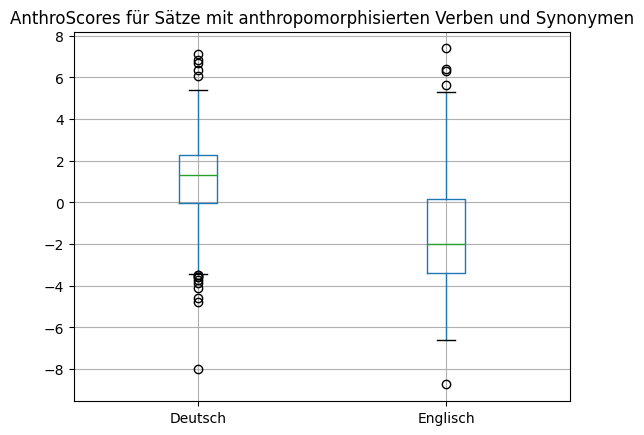

In [ ]:
# plot score distributions, compare languages
text_scores = get_scores_no_duplicates("generated_data/Anthroscore_results/anthro_re_sentence_scores.csv")
translated_scores = get_scores_no_duplicates("generated_data/Anthroscore_results/anthro_re_translated_sentence_scores.csv")

plot_scores(translated_scores, text_scores, "AnthroScores für Sätze mit anthropomorphisierten Verben und Synonymen") 

In [72]:
grouped = text_scores.groupby(["original_term"])
df_mean = grouped["anthroscore"].mean()
print("grouped:",df_mean)
# save grouped stats
df_mean.to_csv("generated_data/Anthroscore_results/anthro_grouped_by_terms.csv")
        

grouped: original_term
AI                        -0.190143
Artificial Intelligence   -1.669027
Chatbot                    2.176390
Copilot                    0.512022
Gemini                     0.348860
KI                         1.298266
Künstliche Intelligenz     1.400685
Sprachmodell               0.329528
Sprachmodelle              1.387546
Transformer                1.524689
chatgpt                    1.010617
gpt                        3.053311
llms                      -0.522419
lms                        1.727304
palm                       0.414778
Name: anthroscore, dtype: float64


In [73]:
grouped = translated_scores.groupby(["original_term"])
df_mean = grouped["anthroscore"].mean()
print("grouped:",df_mean)
# save grouped stats
df_mean.to_csv("generated_data/Anthroscore_results/anthro_translated_grouped_by_terms.csv")

grouped: original_term
AI                        -0.709383
Artificial intelligence   -2.265472
Chatbot                   -2.936150
Copilot                    1.677954
Gemini                    -1.538398
Language model             1.405217
Language models           -1.841545
Transformern              -2.542941
chatgpt                   -1.832854
gpt                       -3.821707
llms                      -1.631378
lms                        2.608003
palm                      -1.203313
Name: anthroscore, dtype: float64
